In [1]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 43.7 MB/s eta 0:00:00


In [46]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Extracting EDF parameters from /content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 183599  =      0.000 ...   367.198 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
<Info | 8 non-empty values
 bads: []
 ch_names: Trig, Fp1-LE, Fp2-LE, F3-LE, F4-LE, C3-LE, C4-LE, P3-LE, P4-LE, ...
 chs: 20 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2025-02-25 22:59:29 UTC
 nchan: 20
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: Azam>
>


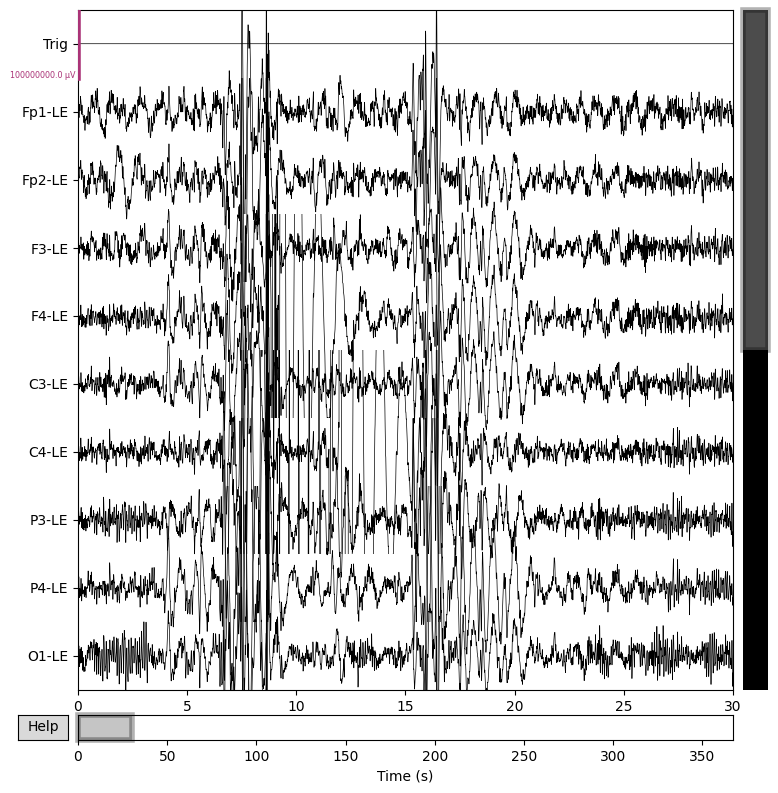

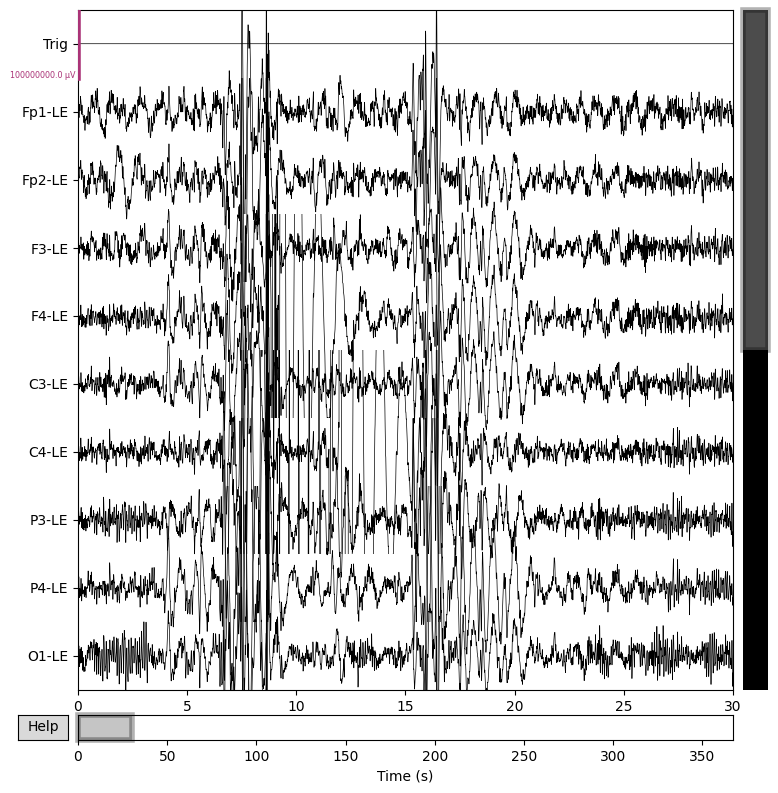

In [50]:
import mne

edf_path = '/content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf'
raw = mne.io.read_raw_edf(edf_path, preload=True)
raw.pick_types(eeg=True)  # Only EEG channels

# View basic info
print(raw.info)
raw.plot(n_channels=10, duration=30, scalings=50)


# **Filter EEG and Extract Frequency Bands**

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, welch

# Select a channel
channel_name = raw.info['ch_names'][1]
data, times = raw.copy().pick_channels([channel_name]).get_data(return_times=True)
fs = raw.info['sfreq']

# Define EEG bands
bands = {
    'Delta': (1, 4),
    'Theta': (4, 8),
    'Alpha': (8, 13),
    'Beta': (13, 30),
    'Gamma': (30, 45)
}

filtered_signals = {}
powers_db = {}

def bandpass_filter(data, fs, low, high):
    b, a = butter(4, [low / (fs/2), high / (fs/2)], btype='band')
    return filtfilt(b, a, data)

# Process each band
for band, (low, high) in bands.items():
    filtered = bandpass_filter(data[0], fs, low, high)
    filtered_signals[band] = filtered
    f, Pxx = welch(filtered, fs, nperseg=fs*2)
    power = np.trapz(Pxx, f)
    powers_db[band] = 10 * np.log10(power)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/tmp/ipython-input-60-1297925317.py:31: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  power = np.trapz(Pxx, f)


# **Plot Time Domain Signals**


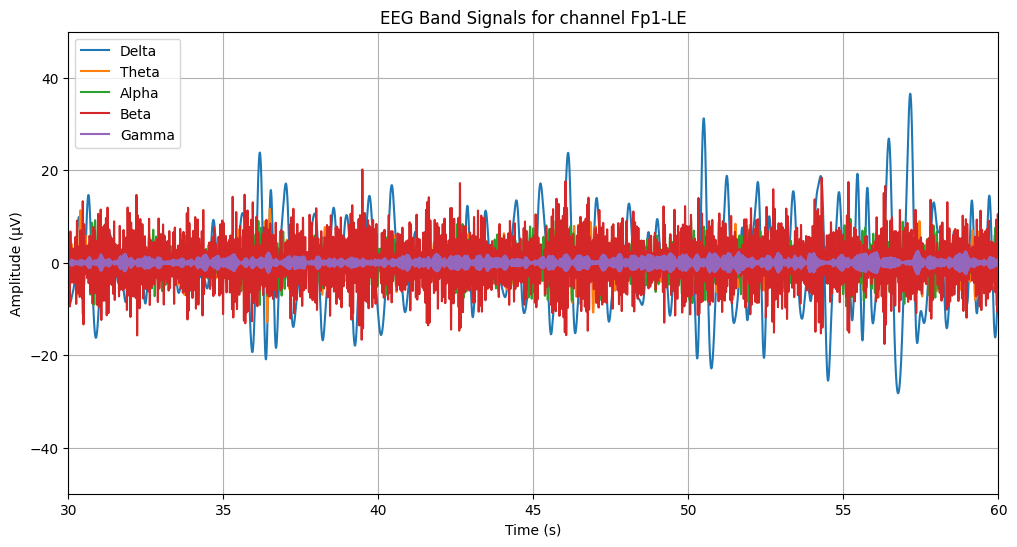

In [67]:
plt.figure(figsize=(12, 6))
for band in bands:
    plt.plot(times, filtered_signals[band], label=band)
plt.xlim(30, 60)  # Zoom to first 10 seconds
plt.ylim(-50, 50)  # Zoom to first 10 seconds

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (µV)")
plt.title(f"EEG Band Signals for channel {channel_name}")
plt.legend()
plt.grid(True)
plt.show()


# **Plot Frequency Spectrum**

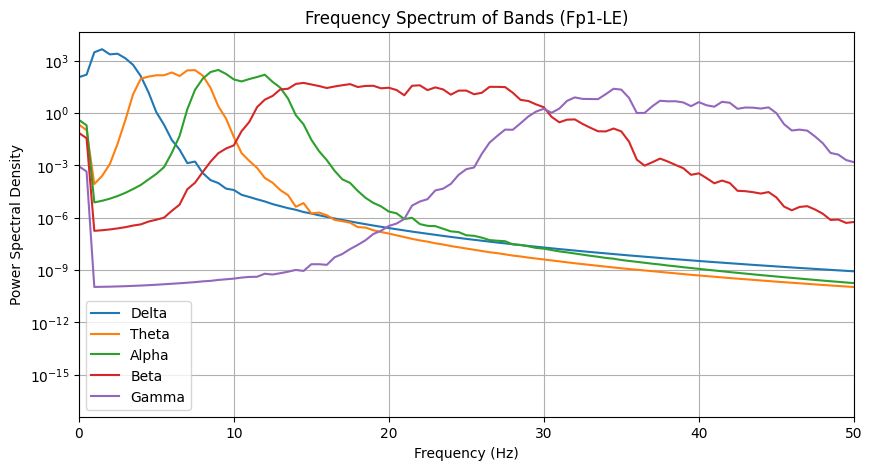

In [68]:
plt.figure(figsize=(10, 5))
for band in bands:
    f, Pxx = welch(filtered_signals[band], fs, nperseg=fs*2)
    plt.semilogy(f, Pxx, label=band)
plt.xlim(0, 50)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title(f"Frequency Spectrum of Bands ({channel_name})")
plt.legend()
plt.grid(True)
plt.show()


# **Bar Graph of Band Power in dB**

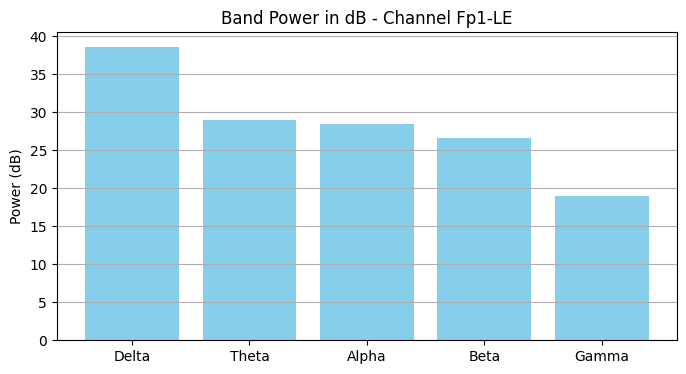

In [72]:
plt.figure(figsize=(8, 4))
plt.bar(powers_db.keys(), powers_db.values(), color='skyblue')
plt.ylabel("Power (dB)")
plt.title(f"Band Power in dB - Channel {channel_name}")
plt.grid(True, axis='y')
plt.show()


# **Time-Frequency Representation (TFR)**

Not setting metadata
36 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 36 events and 5001 original time points ...
0 bad epochs dropped
NOTE: tfr_multitaper() is a legacy function. New code should use .compute_tfr(method="multitaper").


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:   17.1s


No baseline correction applied


[Parallel(n_jobs=1)]: Done  20 out of  20 | elapsed:   18.1s finished


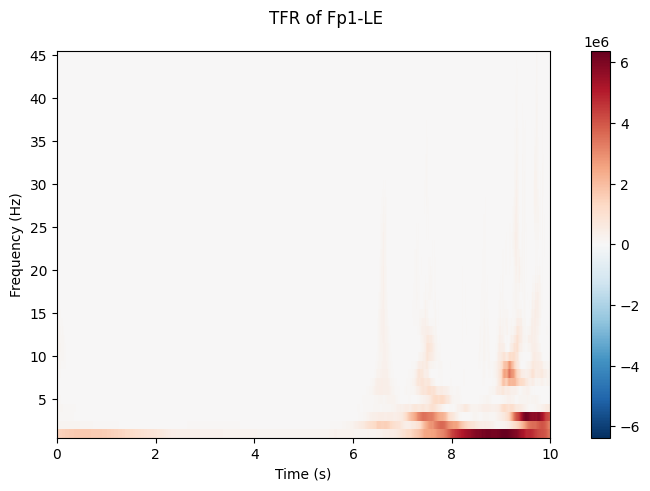

[<Figure size 640x480 with 2 Axes>]

In [71]:
from mne.time_frequency import tfr_multitaper

# Create epochs of 10s length
events = mne.make_fixed_length_events(raw, duration=10)
epochs = mne.Epochs(raw, events, tmin=0, tmax=10, baseline=None, preload=True)

# Apply TFR
power = tfr_multitaper(epochs, freqs=np.linspace(1, 45, 45), n_cycles=4, time_bandwidth=2.0, return_itc=False)
power.plot([1], baseline=None, mode='logratio', title=f"TFR of {channel_name}")


# **Topo plot**

EEG channel type selected for re-referencing
Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...


/tmp/ipython-input-84-901871689.py:5: RuntimeWarning: An average reference projection was already added. The data has been left untouched.
  raw.set_eeg_reference('average', projection=True)


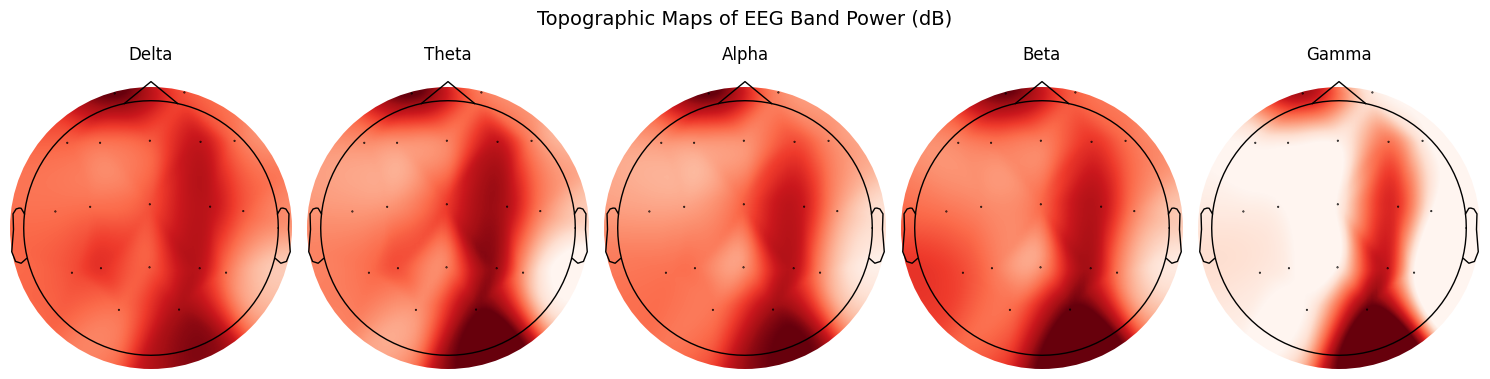

In [84]:
raw.pick('eeg')
raw.drop_channels(['Trig'])
raw.rename_channels(lambda name: name.replace('-LE', ''))  # remove "-LE" suffix
raw.set_montage('standard_1020')  # apply standard electrode positions
raw.set_eeg_reference('average', projection=True)
raw.apply_proj()

# STEP 5: Define frequency bands
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, welch

bands = {
    'Delta': (1, 4),
    'Theta': (4, 8),
    'Alpha': (8, 13),
    'Beta': (13, 30),
    'Gamma': (30, 45)
}

sfreq = raw.info['sfreq']
data, times = raw.get_data(return_times=True)
ch_names = raw.info['ch_names']
band_powers = {}

# Helper function to bandpass filter
def bandpass_filter(data, fs, low, high):
    b, a = butter(4, [low/(fs/2), high/(fs/2)], btype='band')
    return filtfilt(b, a, data)

# STEP 6: Compute power in dB for each channel and band
for band, (low, high) in bands.items():
    power_vals = []
    for ch_data in data:
        filtered = bandpass_filter(ch_data, sfreq, low, high)
        f, Pxx = welch(filtered, fs=sfreq, nperseg=int(sfreq*2))
        power = np.trapezoid(Pxx, f)  # avoid deprecated trapz
        power_db = 10 * np.log10(power + 1e-12)  # avoid log(0)
        power_vals.append(power_db)
    band_powers[band] = np.array(power_vals)

# STEP 7: Plot topographic map for each band
fig, axes = plt.subplots(1, len(bands), figsize=(15, 4))
for i, (band, power_vals) in enumerate(band_powers.items()):
    mne.viz.plot_topomap(power_vals, raw.info, axes=axes[i], show=False, contours=0)
    axes[i].set_title(band)

plt.suptitle("Topographic Maps of EEG Band Power (dB)", fontsize=14)
plt.tight_layout()
plt.show()


# **PSD MNE**

In [86]:
raw_spectrum1 = raw.compute_psd(picks="eeg")

Effective window size : 4.096 (s)


In [87]:
raw_spectrum2 = raw.compute_psd(method="welch", tmin=10, tmax=20, fmin=5, fmax=30, picks="eeg")

Effective window size : 4.096 (s)


Plotting power spectral density (dB=True).


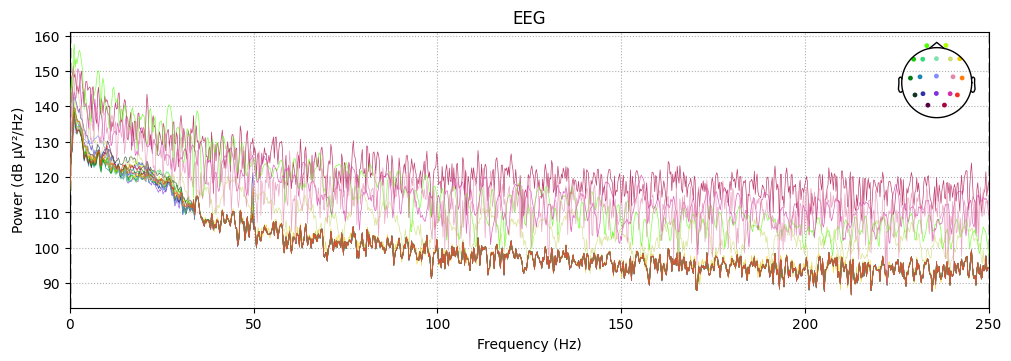

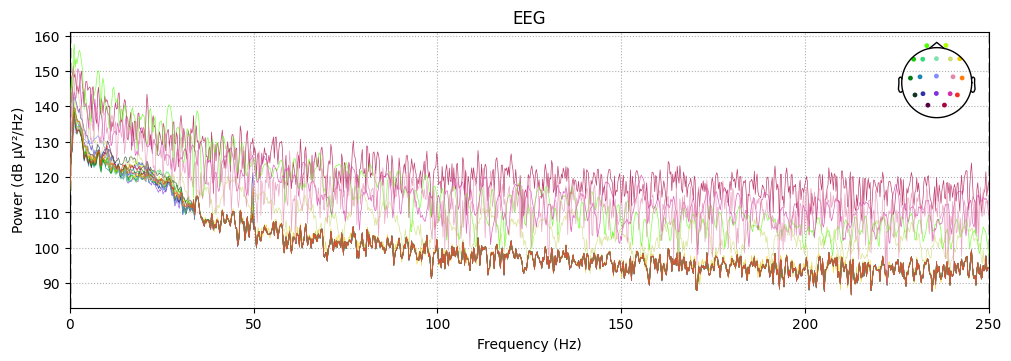

In [88]:
raw_spectrum1.plot(picks="eeg", exclude="bads", amplitude=False)


Plotting power spectral density (dB=True).


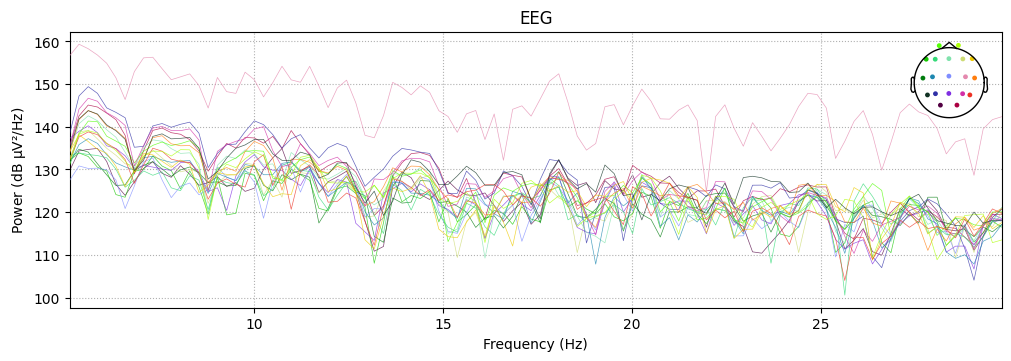

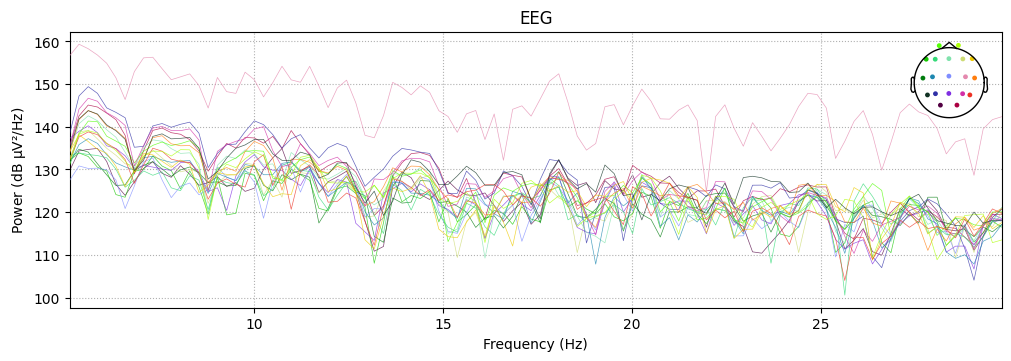

In [89]:
raw_spectrum2.plot(picks="eeg", exclude="bads", amplitude=False)


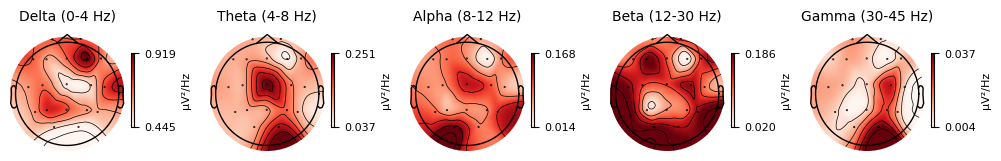

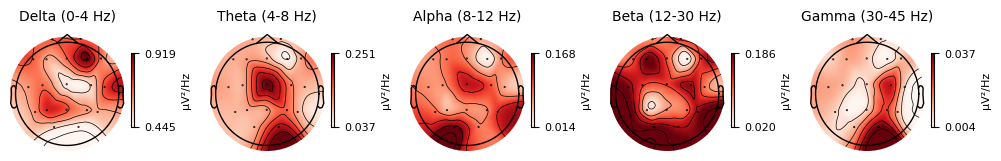

In [113]:
raw_spectrum1.plot_topomap(ch_type="eeg", show=False, normalize=True)

# Frequency and time-frequency sensor analysis


## epoch data

In [102]:
import numpy as np
import mne

raw.pick_types(eeg=True)  # pick only EEG channels
print(raw.info['ch_names'])  # Confirm EEG channels are present
# raw.plot(n_channels=10, duration=10, start=0)

raw.crop(0, 60)  # 60 secs

interval = 3  # sec
sfreq = raw.info['sfreq']
print(sfreq)
n_samples = raw.n_times
n_events = int(n_samples / (interval * sfreq))

tmax = 3  # already define
event_times = np.arange(0, raw.n_times - int(tmax * sfreq), int(interval * sfreq)).astype(int)

# event: (sample, 0, event_id)
event_id = 999
events = np.column_stack((event_times, np.zeros_like(event_times, dtype=int), np.full_like(event_times, event_id)))
print(events)
# epochs = mne.Epochs(raw, events, event_id=event_id, tmin=0, tmax=3, baseline=None, preload=True)
epochs = mne.Epochs(
    raw,
    events,
    event_id=event_id,
    tmin=0,
    tmax=3,
    baseline=None,
    preload=True,
    reject=None,
    flat=None,
    reject_by_annotation=False
)


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']
500.0
[[    0     0   999]
 [ 1500     0   999]
 [ 3000     0   999]
 [ 4500     0   999]
 [ 6000     0   999]
 [ 7500     0   999]
 [ 9000     0   999]
 [10500     0   999]
 [12000     0   999]
 [13500     0   999]
 [15000     0   999]
 [16500     0   999]
 [18000     0   999]
 [19500     0   999]
 [21000     0   999]
 [22500     0   999]
 [24000     0   999]
 [25500     0   999]
 [27000     0   999]
 [28500     0   999]]
Not setting metadata
20 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 20 events and 1501 original time points ...
0 bad epochs dropped


In [104]:
print(epochs.drop_log)
print(raw.annotations)



((), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), ())
<Annotations | 0 segments>


In [105]:
import numpy as np
import mne

raw.crop(0, 60)

# ---- setting ----
epoch_duration = 3.0
step_size = 1.5
sfreq = raw.info['sfreq']

epoch_samples = int(epoch_duration * sfreq)
step_samples = int(step_size * sfreq)

start_samples = np.arange(0, raw.n_times - epoch_samples + 1, step_samples)

event_id = 999
events = np.column_stack((start_samples, np.zeros_like(start_samples), np.full_like(start_samples, event_id)))

epochs = mne.Epochs(
    raw, events, event_id=event_id,
    tmin=0, tmax=epoch_duration,
    baseline=None, preload=True
)

epochs.pick('eeg')

print(epochs)


Not setting metadata
39 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 39 events and 1501 original time points ...
0 bad epochs dropped
<Epochs | 39 events (all good), 0 – 3 s (baseline off), ~8.5 MiB, data loaded,
 '999': 39>


In [106]:
print("Channels:", raw.info['ch_names'])

Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']


NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Applying baseline correction (mode: logratio)


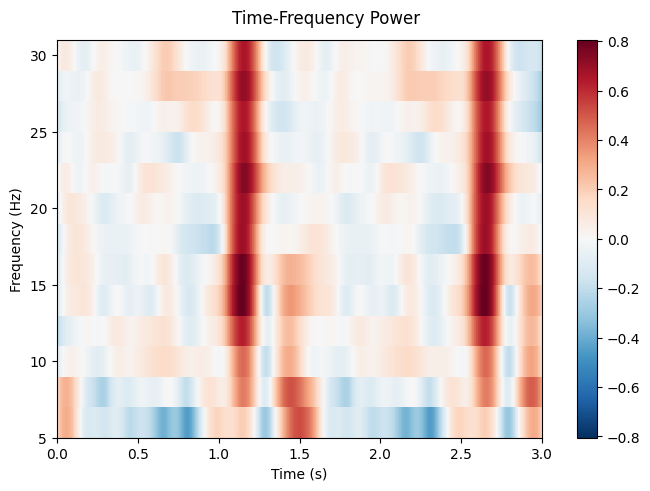

[<Figure size 640x480 with 2 Axes>]

In [109]:
from mne.time_frequency import tfr_morlet
import numpy as np

frequencies = np.arange(6, 31, 2)  # Hz

n_cycles = frequencies / 2.0

power, itc = tfr_morlet(
    epochs,
    freqs=frequencies,
    n_cycles=n_cycles,
    return_itc=True,
    use_fft=True,
    decim=2,
    n_jobs=1
)
power.plot(
    picks=['Fp1'],
    baseline=(0, 0.5),
    mode='logratio',
    title='Time-Frequency Power'
)



    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


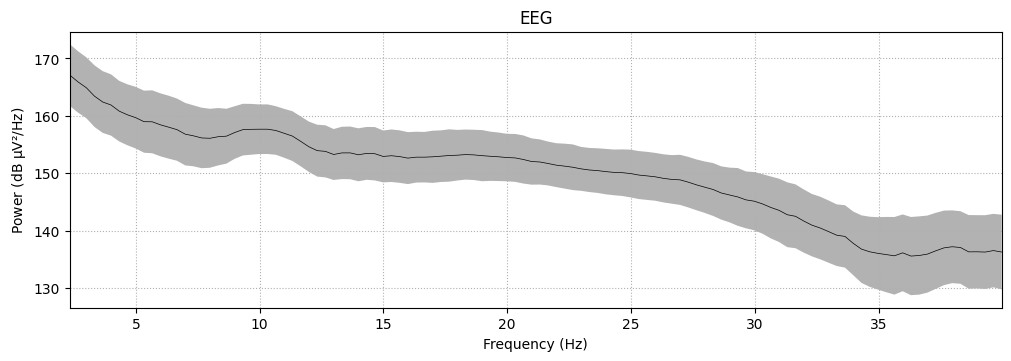

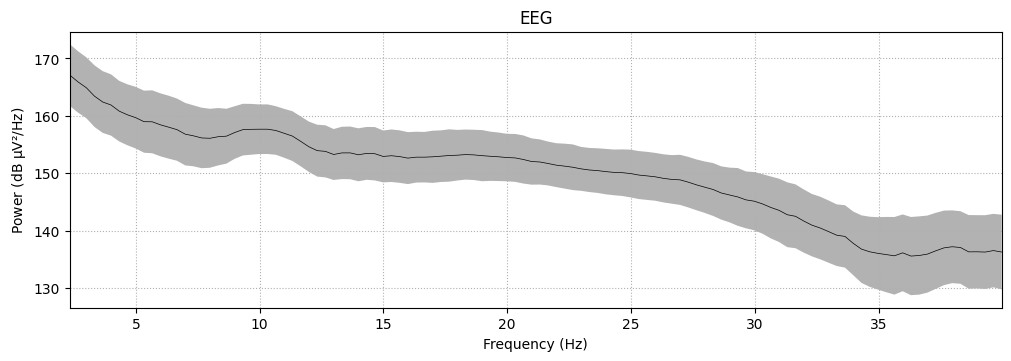

In [110]:
epochs.compute_psd(fmin=2.0, fmax=40.0).plot(
    average=True, amplitude=False, picks="data", exclude="bads"
)

    Using multitaper spectrum estimation with 7 DPSS windows
Averaging across epochs before plotting...


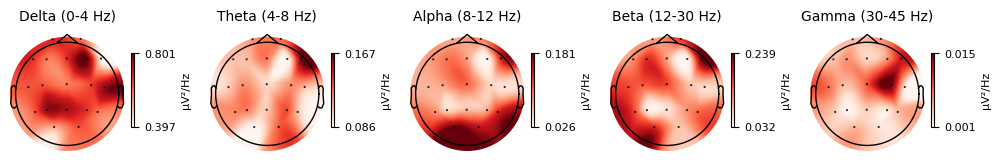

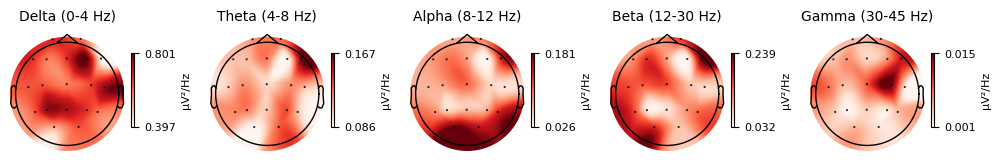

In [112]:
epochs.compute_psd().plot_topomap(normalize=True, contours=0)


Applying baseline correction (mode: logratio)


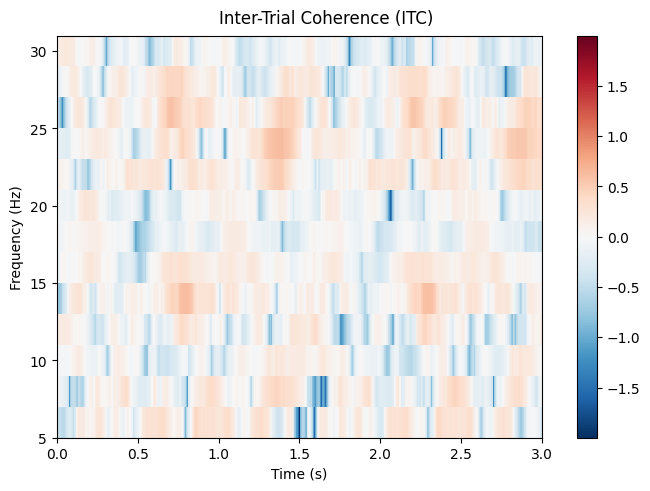

[<Figure size 640x480 with 2 Axes>]

In [115]:
itc.plot(
    picks=['Fp1'],
    baseline=(0, 0.5),
    mode='logratio',
    title='Inter-Trial Coherence (ITC)'
)
